Project Title : Sales Data Analysis 

we have "superstore Sales Dataset" from which we have to make data analysis using python libraries like NumPy, Pandas, Matplotlib, Seaborn and Plotly
In this dataset we have columns like Order ID, Order Date, Ship Date, Ship Mode, Customer ID, Customer Name, Segment, Country/Region and City etc.




Loading or import the useful libraries which needed in this projects 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


In [2]:
df= pd.read_csv('superstore_dataset.csv')

Exploring the Dateset 

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  str    
 2   Order Date      10194 non-null  str    
 3   Ship Date       10194 non-null  str    
 4   Ship Mode       10194 non-null  str    
 5   Customer ID     10194 non-null  str    
 6   Customer Name   10194 non-null  str    
 7   Segment         10194 non-null  str    
 8   Country/Region  10194 non-null  str    
 9   City            10194 non-null  str    
 10  State/Province  10194 non-null  str    
 11  Postal Code     10194 non-null  str    
 12  Region          10194 non-null  str    
 13  Product ID      10194 non-null  str    
 14  Category        10194 non-null  str    
 15  Sub-Category    10194 non-null  str    
 16  Product Name    10194 non-null  str    
 17  Sales           10194 non-null  float64
 1

know about null values in dataset

In [4]:
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

Q1  How many rows and columns? How many missing values?


In [5]:
df.shape
print(f"There are {df.shape[0]} rows and {df.shape[1]} columns in this dataset")

There are 10194 rows and 21 columns in this dataset


In [6]:
#null values in each column
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

Q2 Which is the top 5 selling product category?

In [7]:
df['Product Name'].value_counts().head(5)

Product Name
Staples                       50
Staple envelope               48
Easy-staple paper             46
Avery Non-Stick Binders       20
KI Adjustable-Height Table    20
Name: count, dtype: int64

Q3 Which month had the highest Sales?

In [8]:
def month(txt):
    count = True
    mon = ''
    for i in txt:
        if i =='/':
            count = False
            return mon
        if count==True:
            mon = mon+i
        
        
 
#def finally_mon(txt):
   # y = txt[1::]
   # return y

df['Month'] = df['Order Date'].apply(month).astype(int)


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  str    
 2   Order Date      10194 non-null  str    
 3   Ship Date       10194 non-null  str    
 4   Ship Mode       10194 non-null  str    
 5   Customer ID     10194 non-null  str    
 6   Customer Name   10194 non-null  str    
 7   Segment         10194 non-null  str    
 8   Country/Region  10194 non-null  str    
 9   City            10194 non-null  str    
 10  State/Province  10194 non-null  str    
 11  Postal Code     10194 non-null  str    
 12  Region          10194 non-null  str    
 13  Product ID      10194 non-null  str    
 14  Category        10194 non-null  str    
 15  Sub-Category    10194 non-null  str    
 16  Product Name    10194 non-null  str    
 17  Sales           10194 non-null  float64
 1

In [10]:
def month_name(mon):
    month = {1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'May',6:'Jun',7:'Jul',8:'Aug',9:'Sep',10:'Oct',11:'Nov',12:'Dec'}
    for i in month.keys():
        if mon==i:
            mon=month[i]
    return mon

df['Month'] = df['Month'].apply(month_name)

In [11]:
def month_name(mon):
    month = {1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'May',6:'Jun',7:'Jul',8:'Aug',9:'Sep',10:'Oct',11:'Nov',12:'Dec'}
    for i in month.keys():
        if mon==i:
            mon=month[i]
    return mon

df['Month'] = df['Month'].apply(month_name)

According to this bar graph October month has highest sales


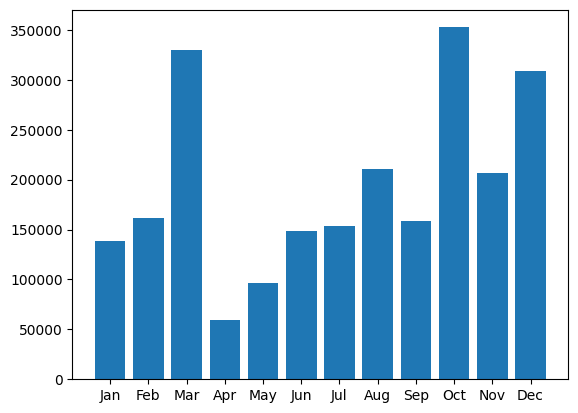

In [12]:
Sales_by_month =df.groupby('Month')['Sales'].sum()
figure = plt.bar(df['Month'].unique(),Sales_by_month)
figure

print(f'According to this bar graph October month has highest sales')


Q4 Make a Bar Chart - Sales by Region

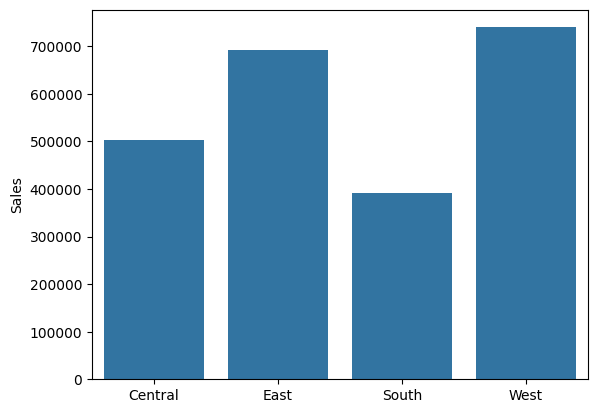

In [13]:
region_sales = df.groupby('Region')['Sales'].sum()
fig = sns.barplot(x=df['Region'].unique(),y= region_sales)

Q5 Make a Heatmap - Correlation between Sales, Profit, Discount,Quantity

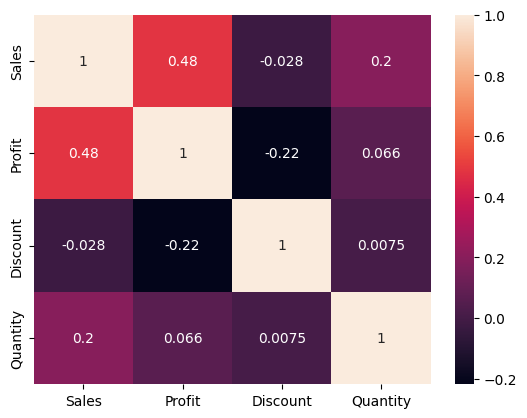

In [14]:
new_df = df[['Sales','Profit','Discount','Quantity']]
fig = sns.heatmap(new_df.corr(),annot = True)

Q6 Make a Boxplot - Profit byCategory, show outliers

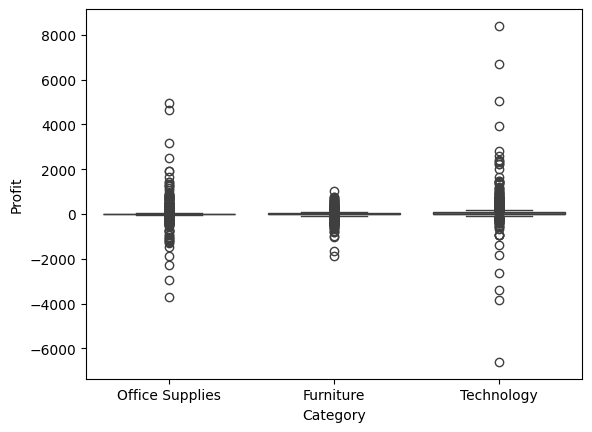

In [15]:
fig = sns.boxplot(x = df['Category'],y = 'Profit', data = df)

Q7 Make an interactive Line chart - Sales over time(Month wise)


In [16]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Month_Num'] = df['Order Date'].dt.month
df['Month'] = df['Order Date'].dt.month_name()
Sales_by_month = df.groupby(['Month_Num','Month'])['Sales'].sum().reset_index()
fig = px.line(Sales_by_month,
              x= 'Month',
              y= 'Sales',
              title ='Sales Over Time(Month Wise)',
              markers = True)


In [17]:
Sales_by_month =df.groupby('Month')['Sales'].sum()
fig = px.line(x=df['Month'].unique(),y= Sales_by_month)
fig.show()

Q8 Make an interactive Pie Chart - Sales by Segment(Consumer, Corporate, Home Office)

In [18]:
seg = df.groupby('Segment')['Sales'].sum().reset_index()
fig =px.pie(seg,names = 'Segment',values = 'Sales', title ='Sales by Segment')
fig.show()